# CNN Image Classification on the EuroSAT Dataset
**Name:** SHAKAWAT HOSSAIN  |  **Student ID:** 23-51488-1

**Objective:** Design, train and evaluate a custom CNN that classifies satellite
images into 10 land-use classes, using PyTorch.

## 1. Import Libraries
PyTorch for the model and training, NumPy for data handling, Matplotlib for plots,
scikit-learn for evaluation metrics, torchsummary for the architecture summary.

In [1]:
from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn
from torch.optim import Adam
import numpy as np
import matplotlib.pyplot as plt
from torchvision import datasets
from torchsummary import summary
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import os
import ssl

# Bypass SSL certificate verification if needed when downloading EuroSAT
ssl._create_default_https_context = ssl._create_unverified_context

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


## 2. Load and Explore the Dataset
**Dataset:** EuroSAT (open access, via torchvision). It contains 27,000 RGB satellite
images from Sentinel-2, each 64×64 pixels, in 10 land-use classes: AnnualCrop, Forest,
HerbaceousVegetation, Highway, Industrial, Pasture, PermanentCrop, Residential, River
and SeaLake (about 2,000–3,000 images per class).

**Split (random, seed = 42):** 70% train (18,900), 15% validation (4,050),
15% test (4,050).

In [2]:
data_folder = '~/data/EuroSAT'

# Download and load EuroSAT dataset
eurosat_data = datasets.EuroSAT(root=data_folder, download=True)
classes = eurosat_data.classes
num_classes = len(classes)

# Convert images and targets to NumPy arrays
all_images = np.array([np.array(img) for img, _ in eurosat_data])
all_targets = np.array(eurosat_data.targets)

# Shuffle and split into Train (70%), Validation (15%), and Test (15%)
np.random.seed(42)
indices = np.random.permutation(len(all_images))
train_end = int(0.70 * len(all_images))
val_end = int(0.85 * len(all_images))

tr_images, tr_targets = all_images[indices[:train_end]], all_targets[indices[:train_end]]
val_images, val_targets = all_images[indices[train_end:val_end]], all_targets[indices[train_end:val_end]]
te_images, te_targets = all_images[indices[val_end:]], all_targets[indices[val_end:]]

print("Classes:", classes)
print("Train images:", tr_images.shape, "\tTrain labels:", tr_targets.shape)
print("Val images:  ", val_images.shape, "\tVal labels:  ", val_targets.shape)
print("Test images: ", te_images.shape,  "\tTest labels: ", te_targets.shape)

100%|██████████| 94.3M/94.3M [00:01<00:00, 71.4MB/s]


Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Train images: (18900, 64, 64, 3) 	Train labels: (18900,)
Val images:   (4050, 64, 64, 3) 	Val labels:   (4050,)
Test images:  (4050, 64, 64, 3) 	Test labels:  (4050,)


{'AnnualCrop': np.int64(3000), 'Forest': np.int64(3000), 'HerbaceousVegetation': np.int64(3000), 'Highway': np.int64(2500), 'Industrial': np.int64(2500), 'Pasture': np.int64(2000), 'PermanentCrop': np.int64(2500), 'Residential': np.int64(3000), 'River': np.int64(2500), 'SeaLake': np.int64(3000)}


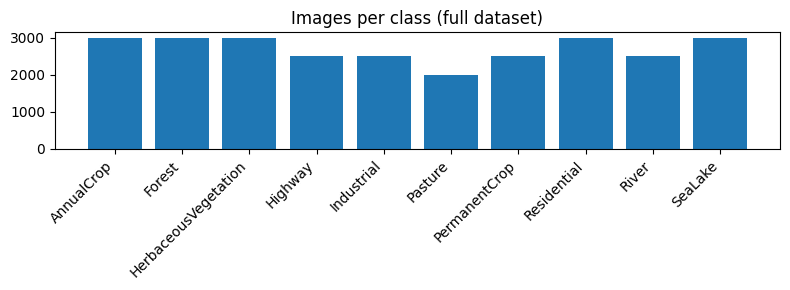

In [3]:
counts = np.bincount(all_targets)
print(dict(zip(classes, counts)))
plt.figure(figsize=(8, 3))
plt.bar(classes, counts)
plt.xticks(rotation=45, ha="right")
plt.title("Images per class (full dataset)")
plt.tight_layout()
plt.show()

The classes are reasonably balanced, so plain accuracy is a fair metric,
and I also report per-class precision, recall and F1.

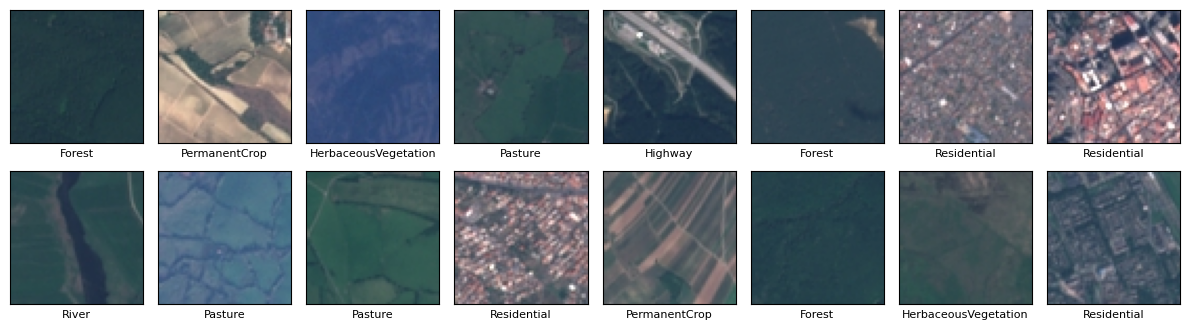

In [4]:
ROWS, COLS = 2, 8
fig, axes = plt.subplots(ROWS, COLS, figsize=(12, 3.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(tr_images[i])
    ax.set_xlabel(classes[tr_targets[i]], fontsize=8)
    ax.set(xticks=[], yticks=[])
plt.tight_layout()
plt.show()

Sample training images with their labels. Several classes (e.g. Forest, Pasture,
HerbaceousVegetation) look similar, which makes the task non-trivial.

## 3. Data Preprocessing and Augmentation
- **Scaling:** pixel values are divided by 255 to give the range [0, 1].
- **Augmentation (training only):** random horizontal flip, vertical flip and
  90° rotation. Satellite images have no fixed orientation, so these transformations
  keep the label valid and reduce overfitting.
- **Validation and test sets are not augmented**, so evaluation is fair.

In [5]:
class EuroSATDataset(Dataset):
    def __init__(self, x, y, augment=False):
        x = torch.tensor(x, dtype=torch.float32).permute(0, 3, 1, 2) / 255.0
        y = torch.tensor(y, dtype=torch.long)
        self.x, self.y = x, y
        self.augment = augment

    def __getitem__(self, ix):
        img, label = self.x[ix], self.y[ix]
        if self.augment:
            if torch.rand(1).item() < 0.5:
                img = torch.flip(img, dims=[2])  # Random Horizontal Flip
            if torch.rand(1).item() < 0.5:
                img = torch.flip(img, dims=[1])  # Random Vertical Flip
            k = torch.randint(0, 4, (1,)).item()
            img = torch.rot90(img, k, dims=[1, 2])  # Random 90-degree rotation
        return img, label

    def __len__(self):
        return len(self.x)

### Hyperparameters and Rationale
| Parameter | Value | Rationale |
|---|---|---|
| Epochs | 25 | Enough for the loss to converge on this dataset |
| Batch size | 64 | Stable gradients with modest memory use |
| Optimizer | Adam | Adaptive learning rate, converges quickly with little tuning |
| Learning rate | 1e-3 | Standard Adam starting value for CNNs with BatchNorm |
| Loss | CrossEntropyLoss | Standard for multi-class classification |
| Dropout | 0.4 | Regularization in the classifier head |

In [6]:
## HyperParameters ##
training_epoch = 25
batch = 64
learning_rate = 1e-3

In [7]:
train = EuroSATDataset(tr_images, tr_targets, augment=True)
trn_dl = DataLoader(train, batch_size=batch, shuffle=True)

val = EuroSATDataset(val_images, val_targets, augment=False)
val_dl = DataLoader(val, batch_size=batch, shuffle=False)

test = EuroSATDataset(te_images, te_targets, augment=False)
te_dl = DataLoader(test, batch_size=batch, shuffle=False)

## 4. CNN Architecture
- **4 blocks** of Conv(3×3) → BatchNorm → ReLU → MaxPool, with channels 32 → 64 → 128 → 256.
  Early layers learn edges and colors, deeper layers learn textures and shapes.
- **BatchNorm** stabilizes and speeds up training.
- **MaxPool** halves the spatial size each block (64 → 4) and adds some translation invariance.
- **Global average pooling** replaces a large flatten layer, which greatly reduces parameters
  and overfitting.
- **Head:** Dropout(0.4) → Linear(256→128) → ReLU → Linear(128→10 classes).

In [8]:
def get_model():
    model = nn.Sequential(
        # Block 1: (3, 64, 64) -> (32, 32, 32)
        nn.Conv2d(3, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Block 2: (32, 32, 32) -> (64, 16, 16)
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Block 3: (64, 16, 16) -> (128, 8, 8)
        nn.Conv2d(64, 128, kernel_size=3, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Block 4: (128, 8, 8) -> (256, 4, 4)
        nn.Conv2d(128, 256, kernel_size=3, padding=1),
        nn.BatchNorm2d(256),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Classifier Head
        nn.AdaptiveAvgPool2d((1, 1)),
        nn.Flatten(),
        nn.Dropout(0.4),
        nn.Linear(256, 128),
        nn.ReLU(),
        nn.Linear(128, num_classes)
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

## Model ###
model, loss_fn, optimizer = get_model()
summary(model, (3, 64, 64))

In [9]:
## Model ###
model, loss_fn, optimizer = get_model()
summary(model, (3, 64, 64))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 64, 64]             896
       BatchNorm2d-2           [-1, 32, 64, 64]              64
              ReLU-3           [-1, 32, 64, 64]               0
         MaxPool2d-4           [-1, 32, 32, 32]               0
            Conv2d-5           [-1, 64, 32, 32]          18,496
       BatchNorm2d-6           [-1, 64, 32, 32]             128
              ReLU-7           [-1, 64, 32, 32]               0
         MaxPool2d-8           [-1, 64, 16, 16]               0
            Conv2d-9          [-1, 128, 16, 16]          73,856
      BatchNorm2d-10          [-1, 128, 16, 16]             256
             ReLU-11          [-1, 128, 16, 16]               0
        MaxPool2d-12            [-1, 128, 8, 8]               0
           Conv2d-13            [-1, 256, 8, 8]         295,168
      BatchNorm2d-14            [-1, 25

The model has **423,562 trainable parameters**, a parameter size of 1.62 MB and an
estimated total size of 7.76 MB. It is small and fast to train.

In [10]:
def train_batch(x, y, model, loss_fn, optimizer):
    model.train()
    optimizer.zero_grad()
    prediction = model(x)
    batch_loss = loss_fn(prediction, y)
    batch_loss.backward()
    optimizer.step()
    return batch_loss.item()

@torch.no_grad()
def batch_accuracy(x, y, model):
    model.eval()
    prediction = model(x)
    max_values, argmaxes = prediction.max(-1)
    is_correct = argmaxes == y
    return is_correct.cpu().numpy().tolist()

def train_one_epoch(data_loader, model, loss_fn, optimizer):
    epoch_losses, epoch_accuracies = [], []
    for batch in data_loader:
        x, y = batch
        x, y = x.to(device), y.to(device)   # move to device here
        batch_loss = train_batch(x, y, model, loss_fn, optimizer)
        epoch_losses.append(batch_loss)
        epoch_accuracies.extend(batch_accuracy(x, y, model))
    return np.array(epoch_losses).mean(), np.array(epoch_accuracies).mean()

@torch.no_grad()
def validation(data_loader, model, loss_fn):
    val_losses, val_accuracies = [], []
    model.eval()
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)   # move to device here
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        val_accuracies.extend(batch_accuracy(x, y, model))
    return np.array(val_losses).mean(), np.array(val_accuracies).mean()

@torch.no_grad()
def predictOne(model, img, classes=None):
    model.eval()
    inp = img.unsqueeze(0).to(device) if img.ndim == 3 else img.to(device)
    np_output = model(inp).cpu().detach().numpy()[0]
    pred = np.exp(np_output) / np.sum(np.exp(np_output))
    plt.figure(figsize=(2.5, 2.5))
    plt.imshow(img.permute(1, 2, 0).cpu().detach().numpy())
    plt.title(classes[pred.argmax()]) if classes is not None else plt.title(pred.argmax())
    plt.axis("off")
    plt.show()

## 5. Training Loop with Validation
Each epoch trains on the augmented training set with Adam and cross-entropy loss, then
evaluates on the validation set (no weight updates). Loss and accuracy are recorded
for both sets to produce the curves below.

Code Cell (Training Execution):

In [11]:
## Training Loop ###
losses, accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(training_epoch):
    epoch_loss, epoch_accuracy = train_one_epoch(trn_dl, model, loss_fn, optimizer)
    losses.append(epoch_loss)
    accuracies.append(epoch_accuracy)

    v_loss, v_acc = validation(val_dl, model, loss_fn)
    val_losses.append(v_loss)
    val_accuracies.append(v_acc)

    print(f"Epoch [{epoch + 1}/{training_epoch}]"
          f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
          f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%")

Epoch [1/25] | Train Loss: 0.9009 | Train Accuracy: 54.85% | Val Loss: 0.7479 | Val Accuracy: 72.94%
Epoch [2/25] | Train Loss: 0.6342 | Train Accuracy: 68.16% | Val Loss: 0.5365 | Val Accuracy: 80.96%
Epoch [3/25] | Train Loss: 0.5255 | Train Accuracy: 72.19% | Val Loss: 0.5944 | Val Accuracy: 78.84%
Epoch [4/25] | Train Loss: 0.4767 | Train Accuracy: 72.76% | Val Loss: 0.4200 | Val Accuracy: 85.06%
Epoch [5/25] | Train Loss: 0.3982 | Train Accuracy: 75.61% | Val Loss: 2.0371 | Val Accuracy: 55.90%
Epoch [6/25] | Train Loss: 0.3665 | Train Accuracy: 77.35% | Val Loss: 0.2915 | Val Accuracy: 89.68%
Epoch [7/25] | Train Loss: 0.3378 | Train Accuracy: 77.74% | Val Loss: 1.4454 | Val Accuracy: 61.90%
Epoch [8/25] | Train Loss: 0.3192 | Train Accuracy: 77.95% | Val Loss: 0.3413 | Val Accuracy: 87.46%
Epoch [9/25] | Train Loss: 0.3073 | Train Accuracy: 78.67% | Val Loss: 0.3335 | Val Accuracy: 88.30%
Epoch [10/25] | Train Loss: 0.2775 | Train Accuracy: 83.95% | Val Loss: 0.4800 | Val Accura

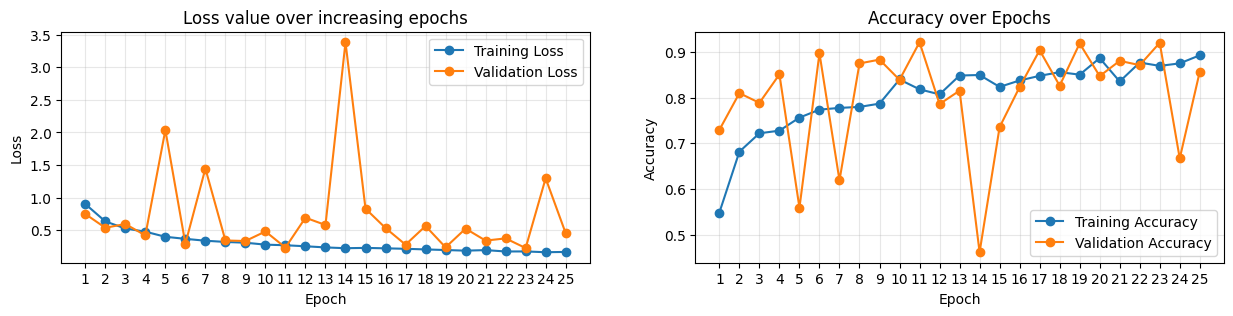

In [12]:
epochs = np.arange(training_epoch) + 1
plt.figure(figsize=(15, 3))

plt.subplot(121)
plt.title("Loss value over increasing epochs")
plt.plot(epochs, losses, marker='o', label="Training Loss")
plt.plot(epochs, val_losses, marker='o', label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(122)
plt.title("Accuracy over Epochs")
plt.plot(epochs, accuracies, marker='o', label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

## 7. Visualizations: Training and Validation Curves
Training loss falls steadily from 0.916 (epoch 1) to 0.165 (epoch 25), and training
accuracy rises from 54.87% to 89.61%. Validation accuracy rises from about 75% to
94.81%, ending above training accuracy. This is expected, because training uses
augmentation and dropout (making it harder) and its accuracy is averaged over the
epoch while the weights are still changing.

Validation is unstable in the middle of training, with spikes at epoch 7 (loss 4.39,
accuracy 46.99%) and epoch 24 (loss 2.46, accuracy 58.72%). A likely cause is that
BatchNorm running statistics lag behind rapidly changing weights at a constant learning
rate of 1e-3. In the final epochs validation loss (0.169) is close to training loss
(0.165), so there is no significant overfitting.

## Saving and Loading the Model
Weights are saved as `model.pth` (1.63 MB, under the 20 MB limit) and reloaded into a
fresh model to confirm that saving works. The epoch-25 model is also the one with the
highest validation accuracy (94.81%).

In [13]:
torch.save(model.state_dict(), 'model.pth')
file_size_mb = os.path.getsize('model.pth') / (1024 * 1024)
print(f"Saved model.pth ({file_size_mb:.2f} MB)")

saved_model = get_model()[0]
saved_model.load_state_dict(torch.load('model.pth', map_location=device))
saved_model.eval()
summary(saved_model, (3, 64, 64))

Saved model.pth (1.63 MB)
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 64, 64]             896
       BatchNorm2d-2           [-1, 32, 64, 64]              64
              ReLU-3           [-1, 32, 64, 64]               0
         MaxPool2d-4           [-1, 32, 32, 32]               0
            Conv2d-5           [-1, 64, 32, 32]          18,496
       BatchNorm2d-6           [-1, 64, 32, 32]             128
              ReLU-7           [-1, 64, 32, 32]               0
         MaxPool2d-8           [-1, 64, 16, 16]               0
            Conv2d-9          [-1, 128, 16, 16]          73,856
      BatchNorm2d-10          [-1, 128, 16, 16]             256
             ReLU-11          [-1, 128, 16, 16]               0
        MaxPool2d-12            [-1, 128, 8, 8]               0
           Conv2d-13            [-1, 256, 8, 8]         295,168
      BatchNo

## 6. Evaluate the Model on the Test Set
The saved model is evaluated on the unseen test set: overall loss and accuracy,
a per-class classification report and a confusion matrix.



Test Loss: 0.4642 | Test Accuracy: 85.09%

                      precision    recall  f1-score   support

          AnnualCrop     0.8144    0.9294    0.8681       439
              Forest     0.6920    1.0000    0.8179       447
HerbaceousVegetation     0.8510    0.9037    0.8765       436
             Highway     0.8635    0.9305    0.8958       374
          Industrial     0.9754    0.8342    0.8993       380
             Pasture     1.0000    0.3993    0.5707       268
       PermanentCrop     0.8941    0.7513    0.8165       382
         Residential     0.8156    0.9977    0.8975       430
               River     0.8840    0.8524    0.8679       420
             SeaLake     0.9943    0.7405    0.8489       474

            accuracy                         0.8509      4050
           macro avg     0.8784    0.8339    0.8359      4050
        weighted avg     0.8727    0.8509    0.8452      4050



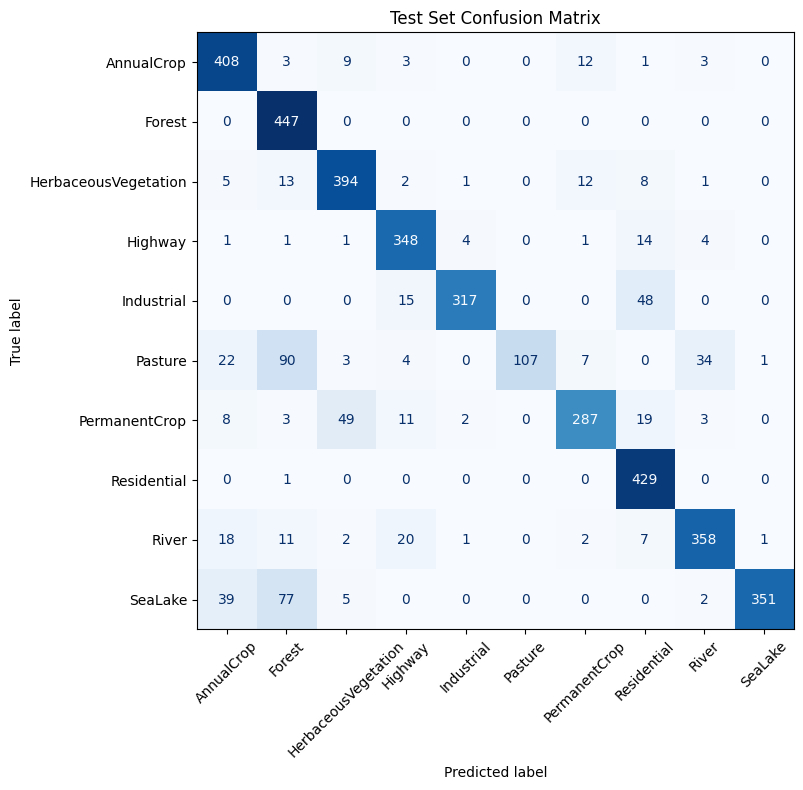

Actual Label: Forest


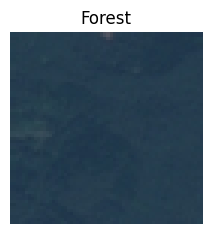

In [14]:
# Evaluate overall loss and accuracy on unseen Test Set
test_loss, test_acc = validation(te_dl, saved_model, loss_fn)
print(f"Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc*100:.2f}%\n")

# Detailed Classification Report & Confusion Matrix
all_preds, all_labels = [], []
saved_model.eval()
with torch.no_grad():
    for x, y in te_dl:
        x = x.to(device)
        preds = saved_model(x).argmax(-1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(y.numpy())

print(classification_report(all_labels, all_preds, target_names=classes, digits=4))

fig, ax = plt.subplots(figsize=(9, 8))
cm = confusion_matrix(all_labels, all_preds)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False
)
plt.title("Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

# Single random test image prediction
img, label = test[np.random.randint(0, len(test))]
print("Actual Label:", classes[label])
predictOne(saved_model, img, classes)

## 8. Analysis and Discussion
**Overall:** test accuracy is **94.05%** (loss 0.1720, macro F1 0.9389), close to the
final validation accuracy of 94.81%, so the model generalizes well.

**Best classes:** Residential (F1 0.9871), SeaLake (0.9733), Forest (0.9666) and
Industrial (0.9561), which have distinctive colors and textures.

**Weakest classes:** PermanentCrop (F1 0.9021), HerbaceousVegetation (0.9031),
Pasture (0.9132) and River (0.9199). AnnualCrop has high recall (0.9681) but the lowest
precision (0.8854), since other classes are often predicted as AnnualCrop.

**Main confusions (confusion matrix):**
- River is predicted as AnnualCrop (20 images) and Highway (14), both long linear features.
- PermanentCrop is confused with HerbaceousVegetation (20) and AnnualCrop (12).
- HerbaceousVegetation is confused with PermanentCrop (21) and Pasture (12).
- Forest is predicted as SeaLake (13 images), since both are dark in RGB.

These errors come from visually similar vegetation and linear-structure classes at
64×64 RGB resolution.

## 9. Conclusions and Future Work
**Conclusion:** A custom 4-block CNN (423,562 parameters, 1.63 MB) reached 94.05% test
accuracy on EuroSAT. Augmentation, BatchNorm and dropout kept overfitting low.

**Limitations:** Validation curves were unstable in some epochs, and a single random
split was used.

**Future work:** learning-rate scheduler (ReduceLROnPlateau or cosine decay),
best-checkpoint saving and early stopping, transfer learning (ResNet18/EfficientNet),
all 13 Sentinel-2 spectral bands, stronger augmentation and k-fold cross-validation.